# Super-resolution microscopy: SIM, STED and single molecule localization

A wide field fluorescence microscope transmits object frequencies only up
to the OTF cutoff $k_c = 2k_0\mathrm{NA}$ (in spatial frequency
$2\mathrm{NA}/\lambda$): nothing finer than about $\lambda/(2\mathrm{NA})$,
roughly 190 nm for green light and an NA 1.4 oil objective, makes it into
the image (notebooks 17, 52 and 54). Fluorescence offers three ways around
this, and all three are simulated here:

- **Structured illumination (SIM).** Exciting the sample with a fine
  sinusoidal pattern mixes object frequencies $k$ down to $k - k_p$, into
  the pass band, where they show up as moiré. Nine raw images (three
  pattern angles, three phases) let us separate the mixed bands and move
  them back to their place in k-space: the OTF support grows to
  $k_c + k_p \approx 2k_c$, double the wide field resolution.
- **Stimulated emission depletion (STED).** A second, red-shifted beam
  with a doughnut-shaped focus switches the fluorophores off everywhere
  except at its central zero. Because the switch-off saturates, the
  remaining spot shrinks without limit as the depletion intensity grows,
  $d \approx \lambda/(2\mathrm{NA}\sqrt{1 + I/I_s})$. The doughnut comes
  from a vortex phase plate and the vectorial focus of a high NA lens, and
  its zero is only a true zero for one of the two circular polarizations.
- **Single molecule localization (PALM/STORM).** If only a few,
  well-separated molecules glow at a time, each one's position can be
  found far more precisely than the PSF width, to about $\sigma/\sqrt{N}$
  with $N$ photons. Notebook 18 showed this for the centroid; here pixels,
  background and the maximum likelihood fit are added, and a
  super-resolved image is assembled from thousands of localizations.

| Function (`pyoptics.superresolution`) | Purpose |
|---|---|
| `sim_pattern()`, `sim_images()` | sinusoidal excitation and the raw SIM images |
| `sim_bands()` | separation of the three bands per angle from the three phases |
| `shift_spectrum()` | moves a band to its true place in k-space (any shift) |
| `sim_reconstruct()`, `wiener_deconvolution()` | generalized Wiener filter for SIM and its wide field counterpart |
| `otf_support()`, `ideal_otf()` | the region of k-space covered; the diffraction limited OTF |
| `vortex_focus()` | vectorial focus with a helical phase and any polarization |
| `sted_psf()`, `sted_fwhm()` | effective STED PSF; the square root law |
| `gaussian_spot()`, `localize()`, `localization_precision()` | pixelated spots, centroid/least squares/maximum likelihood fits, Mortensen's precision |

The OTF comes from `imaging.get_otf()`, the high NA focus from
`propagators.vectorial_mansuripur()` (notebook 02), the vortex from the
helical phase of notebook 69, and camera noise from `processing`
(notebook 18).

Sections: 1. structured illumination: moiré, raw images, band separation,
OTF support, reconstruction and what wrong parameters do; 2. STED: the
doughnut and its polarization, the effective PSF against saturation,
imperfect zeros, an image; 3. localization microscopy: precision against
photons and background, a PALM image.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
from scipy.ndimage import map_coordinates

from pyoptics import sketch, vortices
from pyoptics import superresolution as sr
from pyoptics.fft import FT
from pyoptics.imaging import get_otf
from pyoptics.processing import CameraNoiser
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 72, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
_t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](_t[:, 0])[:, :3])*np.clip(_t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
t_start = time.time()

NA, n_oil = 1.4, 1.518          # oil immersion objective
wl_exc, wl_em = 0.488, 0.520    # excitation and emission (GFP-like), µm
k_em = 2*np.pi/wl_em
k_c = 2*NA*k_em                 # OTF cutoff (rad/µm)


def fwhm(coord, profile):
    # full width at half maximum of the central peak, linear interpolation
    p = profile/np.max(profile)
    i0 = np.argmax(p)
    r = i0
    while p[r + 1] >= 0.5:
        r += 1
    l = i0
    while p[l - 1] >= 0.5:
        l -= 1
    xr = np.interp(0.5, [p[r + 1], p[r]], [coord[r + 1], coord[r]])
    xl = np.interp(0.5, [p[l - 1], p[l]], [coord[l - 1], coord[l]])
    return xr - xl


print(f"wide field cutoff: period 2π/k_c = {2*np.pi/k_c*1000:.0f} nm")

wide field cutoff: period 2π/k_c = 186 nm


## 1. Structured illumination

### The setup

In the classic grating SIM (Heintzmann and Cremer 1999, Gustafsson 2000) a
phase grating sits in a plane conjugate to the specimen. A mask in the
next pupil plane blocks the zeroth order; the $\pm 1$st orders are focused
near the edge of the objective pupil and leave the objective as two plane
waves at $\pm\theta$ that interfere in the specimen. Their fringes
$1 + m\cos(\mathbf{k}_p\cdot\mathbf{r} + \varphi)$ have the wave number
$k_p = 2k_0 n\sin\theta \le 2k_0\mathrm{NA}$ at the excitation wavelength:
the finest pattern the objective can make is just about as fine as the
finest detail it can transmit. The grating is rotated (three angles) and
shifted (three phases); the camera records one wide field image each.

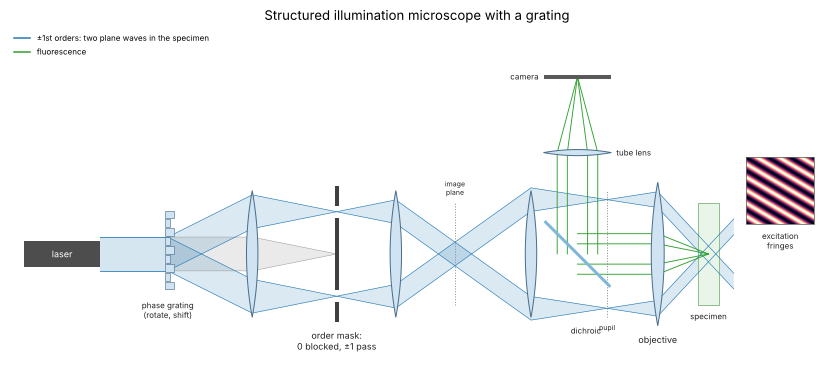

In [2]:
fig, ax = plt.subplots(figsize=(12, 5.2))
sketch.sim_microscope(ax, title="Structured illumination microscope with a grating")
plt.tight_layout()

### Moiré: high frequencies made visible

The fluorescence is proportional to the excitation, so the camera sees
the incoherent image of the product of the dye density $s(\mathbf{r})$ and
the pattern. In k-space the product is a sum of three copies of the
object spectrum,

$$\tilde D(\mathbf{k}) = H(\mathbf{k})\Big[\tilde S(\mathbf{k})
  + \tfrac{m}{2}e^{i\varphi}\tilde S(\mathbf{k} - \mathbf{k}_p)
  + \tfrac{m}{2}e^{-i\varphi}\tilde S(\mathbf{k} + \mathbf{k}_p)\Big],$$

and the OTF $H$ now passes object frequencies up to $|\mathbf{k}| = k_c +
k_p$, shifted down by $\mathbf{k}_p$. A grating finer than the wide field
limit, invisible on its own, shows up as coarse moiré fringes at the
difference frequency. Here the pattern is made at 90 % of the largest
possible $k_p = 2k_0\mathrm{NA}$ at 488 nm, and the emission OTF is
`imaging.get_otf()` at 520 nm, which agrees with the analytic OTF of a
circular pupil.

OTF vs. analytic circular pupil: max deviation 2.0e-03
pattern period 194 nm (k_p = 0.959 k_c), SIM limit 2π/(k_c + k_p) = 95 nm


expected moiré period 2π/|k_s - k_p| = 261 nm


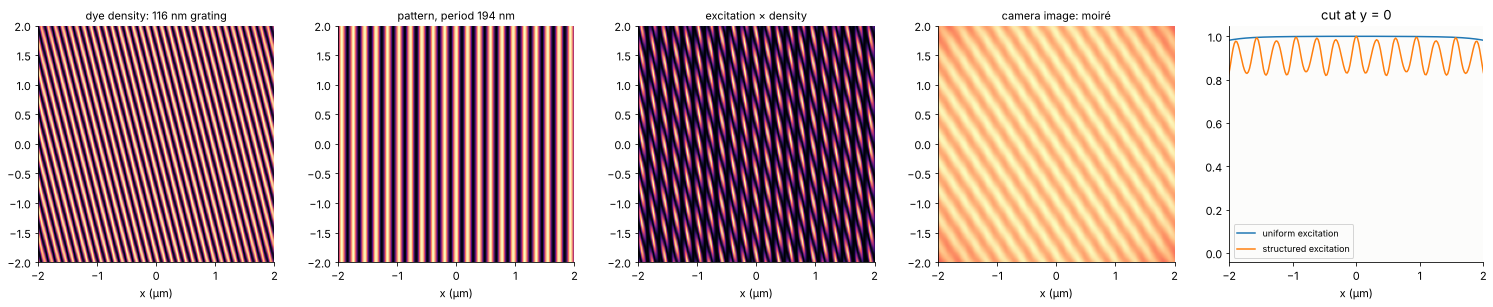

In [3]:
N, dx = 512, 0.02               # 10.24 µm field; the SIM spectrum reaches 2 k_c: dx <= 46 nm
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
K_x, K_y = freq_grid(x, y)
K = np.hypot(K_x, K_y)
otf = np.real(get_otf(x, y, NA, k_em))
k_p = 0.9*2*NA*2*np.pi/wl_exc
print(f"OTF vs. analytic circular pupil: max deviation {np.abs(otf - sr.ideal_otf(x, y, k_c)).max():.1e}")
print(f"pattern period {2*np.pi/k_p*1000:.0f} nm (k_p = {k_p/k_c:.3f} k_c), "
      f"SIM limit 2π/(k_c + k_p) = {2*np.pi/(k_c + k_p)*1000:.0f} nm")

window = np.exp(-(np.hypot(X, Y)/3.5)**8)             # dark border: the field is periodic
k_s = 1.6*k_c                                         # a 116 nm grating
grating = window*(1 + np.cos(k_s*(np.cos(0.25)*X + np.sin(0.25)*Y)))
pattern = sr.sim_pattern(x, y, k_p, 0.0, 0.0)
wf_g = sr.sim_images(grating, x, y, otf, k_p, [0.0], [0.0])[0, 0]
plain = np.real(np.fft.fftshift(np.fft.ifft2(np.fft.fft2(np.fft.ifftshift(grating))*
                                             np.fft.ifftshift(otf))))
fig, axes = plt.subplots(1, 5, figsize=(21, 4.4))
for ax, img, title in zip(axes[:4], (grating, pattern, grating*pattern, wf_g),
                          ("dye density: 116 nm grating", f"pattern, period {2*np.pi/k_p*1000:.0f} nm",
                           "excitation × density", "camera image: moiré")):
    ax.imshow(img, extent=(x[0], x[-1], y[0], y[-1]), cmap="magma")
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_title(title, fontsize=11)
    ax.set_xlabel("x (µm)")
ax = axes[4]
for img, name in ((plain, "uniform excitation"), (wf_g, "structured excitation")):
    ax.plot(x, img[N//2]/img.max(), lw=1.5, label=name)
ax.set_xlim(-2, 2); ax.set_xlabel("x (µm)"); ax.set_title("cut at y = 0"); ax.legend(fontsize=9)
plt.tight_layout()
moire = 2*np.pi/np.hypot(k_s*np.cos(0.25) - k_p, k_s*np.sin(0.25))
print(f"expected moiré period 2π/|k_s - k_p| = {moire*1000:.0f} nm")

With uniform excitation the 116 nm grating gives a flat grey image; under
the pattern its frequency $\mathbf{k}_s$ appears at $\mathbf{k}_s -
\mathbf{k}_p$, as fringes with a period of about 260 nm, inclined against
both. The moiré carries the information
about the fine grating; the task is to decode it.

### Nine raw images

The test sample is a Siemens star with 36 spoke pairs (period
$2\pi r/36$ at the radius $r$) and some filaments. Three pattern angles
60° apart (rotated slightly away from the grid axes) and three phases
$0, 2\pi/3, 4\pi/3$ give nine images; each is scaled to a peak of 300
photons and recorded with shot noise.

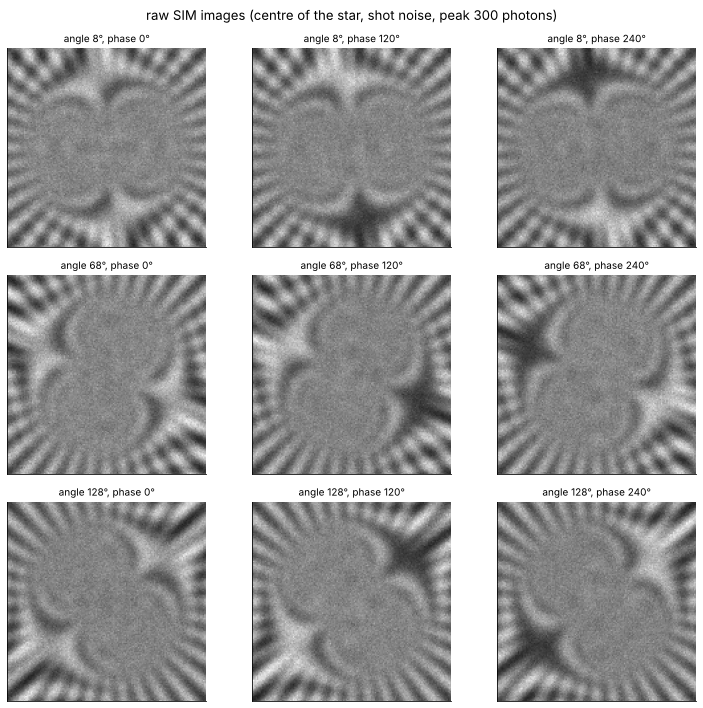

In [4]:
R, PHI = np.hypot(X, Y), np.arctan2(Y, X)
star = 1.0*(np.cos(36*PHI) > 0)*(R < 3.2)
rng = np.random.default_rng(3)
fil = np.zeros_like(X)
for _ in range(10):                          # random smooth filaments (~25 nm thick)
    t = np.linspace(0, 1, 400)
    p0, d0 = rng.uniform(-4, 4, 2), rng.uniform(0, 2*np.pi)
    curv = rng.normal(0, 1.2)
    xs = p0[0] + np.cumsum(np.cos(d0 + curv*t))*0.02
    ys = p0[1] + np.cumsum(np.sin(d0 + curv*t))*0.02
    ix, iy = np.round((xs - x[0])/dx).astype(int), np.round((ys - y[0])/dx).astype(int)
    ok = (ix >= 0) & (ix < N) & (iy >= 0) & (iy < N)
    fil[iy[ok], ix[ok]] = 1.0
sample = np.clip(star + 0.8*fil*(R > 3.3), 0, 1)*window

angles = np.deg2rad(8.0) + np.arange(3)*np.pi/3
phases = np.arange(3)*2*np.pi/3
clean = sr.sim_images(sample, x, y, otf, k_p, angles, phases)
scale = 300/clean.max()
noisy = CameraNoiser("poisson", rng=1)(clean.reshape(9, N, N).transpose(1, 2, 0)*scale)
raw = noisy.transpose(2, 0, 1).reshape(3, 3, N, N)

fig, axes = plt.subplots(3, 3, figsize=(10.5, 10))
for a in range(3):
    for j in range(3):
        ax = axes[a, j]
        ax.imshow(raw[a, j], extent=(x[0], x[-1], y[0], y[-1]), cmap="gray")
        ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"angle {np.rad2deg(angles[a]):.0f}°, phase {np.rad2deg(phases[j]):.0f}°",
                     fontsize=10)
fig.suptitle("raw SIM images (centre of the star, shot noise, peak 300 photons)")
plt.tight_layout()

### Band separation

For each angle the three phases give three linear equations for the three
bands $H(\mathbf{k})\tilde S(\mathbf{k} - j\mathbf{k}_p)$, $j = -1, 0, 1$,
with the matrix $M_{nj} = c_j e^{ij\varphi_n}$ ($c_0 = 1$, $c_{\pm1} =
m/2$); `sim_bands()` inverts it. Since we know the true sample here, the
separation can be checked exactly against $H(\mathbf{k})\tilde
S(\mathbf{k} - j\mathbf{k}_p)$ computed directly from the dye density
(noise-free images).

band separation, relative max error for j = -1, 0, 1: 1.8e-14, 7.9e-16, 2.9e-14


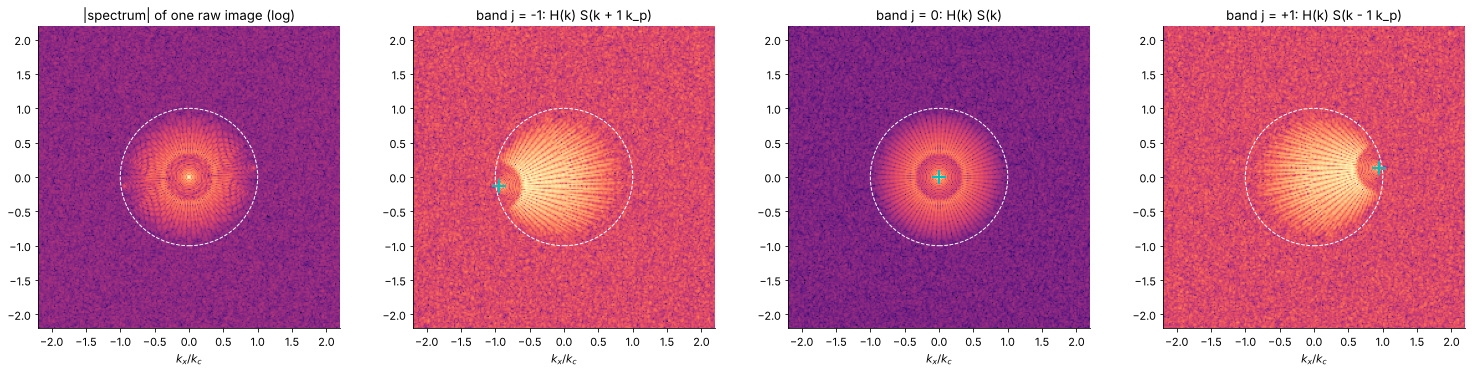

In [5]:
bands_clean = sr.sim_bands(clean, phases)
S_tilde = FT(sample)
a = 0
errs = []
for i, j in enumerate((-1, 0, 1)):
    c, s = np.cos(angles[a]), np.sin(angles[a])
    # H(k) S(k - j k_p): the sample times exp(+i j k_p.r), then the OTF
    expected = otf*FT(sample*np.exp(1j*j*k_p*(c*X + s*Y)))
    errs.append(np.abs(bands_clean[a, i] - expected).max()/np.abs(expected).max())
print("band separation, relative max error for j = -1, 0, 1:", ", ".join(f"{e:.1e}" for e in errs))

bands = sr.sim_bands(raw, phases)
ext_k = (K_x[0, 0]/k_c, K_x[0, -1]/k_c, K_y[0, 0]/k_c, K_y[-1, 0]/k_c)
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
axes[0].imshow(np.log10(np.abs(FT(raw[0, 0])) + 1), extent=ext_k, cmap="magma")
axes[0].set_title("|spectrum| of one raw image (log)")
for ax, i, j in zip(axes[1:], range(3), (-1, 0, 1)):
    ax.imshow(np.log10(np.abs(bands[0, i]) + 1), extent=ext_k, cmap="magma")
    ax.set_title(f"band j = {j:+d}: H(k) S(k {'-' if j > 0 else '+'} {abs(j)} k_p)" if j else
                 "band j = 0: H(k) S(k)")
for ax in axes:
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="w", ls="--", lw=1))
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_xlabel("$k_x/k_c$")
for ax, j in zip(axes[1:], (-1, 0, 1)):
    ax.plot(j*k_p/k_c*np.cos(angles[0]), j*k_p/k_c*np.sin(angles[0]), "c+", ms=14, mew=2)
plt.tight_layout()

The separation is exact up to rounding. All three bands live inside the
OTF circle (dashed, radius $k_c$), and they look alike, but they are not:
the spokes of the star appear in the $j = \pm 1$ bands with their centre
(the zero frequency of the object, cyan cross) moved to $\mp\mathbf{k}_p$.

### Shifting the bands and the OTF support

`shift_spectrum()` moves band $j$ by $-j\mathbf{k}_p$, so it becomes
$H(\mathbf{k} + j\mathbf{k}_p)\tilde S(\mathbf{k})$ at the right place;
the shift multiplies the band's image with $e^{-ij\mathbf{k}_p\cdot
\mathbf{r}}$, which works for any $\mathbf{k}_p$, not only for grid
frequencies. Seven OTF copies (the centre and six shifted ones) now cover
k-space. Along the pattern directions the support reaches $k_c + k_p$;
in between, at 30° from the nearest pattern direction, the boundary of the
shifted circle lies at

$$k_\mathrm{min} = k_p\cos 30° + \sqrt{k_c^2 - k_p^2\sin^2 30°},$$

which sets the worst-case resolution of a three-angle SIM.

wide field support: radius 0.988 ... 0.991 k_c (analytic 1)
SIM support: inscribed radius 1.701 k_c (analytic 1.708), largest 1.950 k_c (analytic 1.959), area ratio 3.55


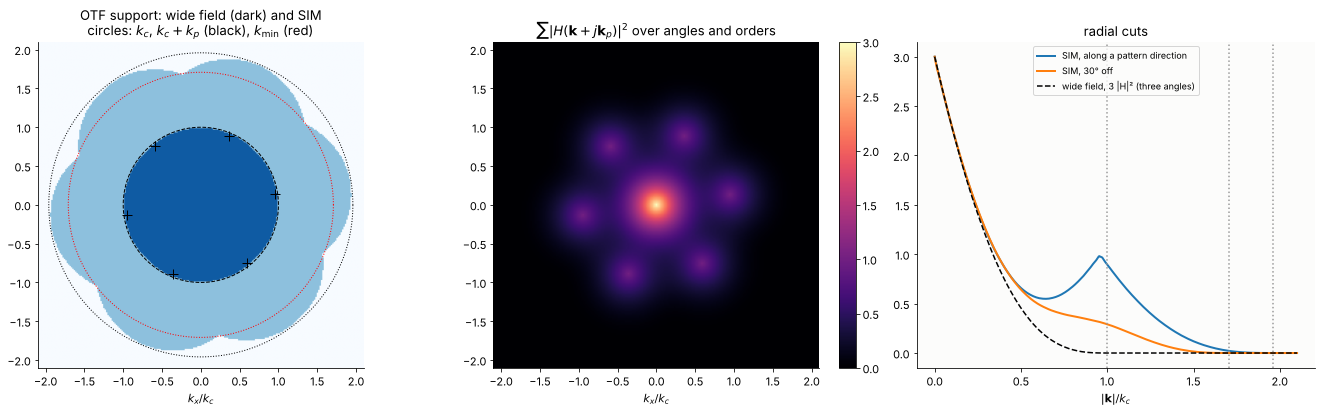

In [6]:
sup_wf = sr.otf_support(otf, x, y, 0.0, [0.0])
sup_sim = sr.otf_support(otf, x, y, k_p, angles)
k_min = k_p*np.cos(np.pi/6) + np.sqrt(k_c**2 - (k_p*np.sin(np.pi/6))**2)
print(f"wide field support: radius {K[~sup_wf].min()/k_c:.3f} ... {K[sup_wf].max()/k_c:.3f} k_c (analytic 1)")
print(f"SIM support: inscribed radius {K[~sup_sim].min()/k_c:.3f} k_c (analytic {k_min/k_c:.3f}), "
      f"largest {K[sup_sim].max()/k_c:.3f} k_c (analytic {(k_c + k_p)/k_c:.3f}), "
      f"area ratio {sup_sim.sum()/sup_wf.sum():.2f}")

otf_sum = sum(np.abs(sr.shift_spectrum(otf, x, y, j*k_p*np.cos(a), j*k_p*np.sin(a)))**2
              for a in angles for j in (-1, 0, 1))
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
axes[0].imshow(sup_wf + 1.0*sup_sim, extent=ext_k, cmap="Blues", vmin=0, vmax=2.4)
th = np.linspace(0, 2*np.pi, 400)
axes[0].plot(np.cos(th), np.sin(th), "k--", lw=1)
axes[0].plot((k_c + k_p)/k_c*np.cos(th), (k_c + k_p)/k_c*np.sin(th), "k:", lw=1)
axes[0].plot(k_min/k_c*np.cos(th), k_min/k_c*np.sin(th), "r:", lw=1)
for a in angles:
    for j in (-1, 1):
        axes[0].plot(j*k_p/k_c*np.cos(a), j*k_p/k_c*np.sin(a), "k+", ms=10)
axes[0].set_title("OTF support: wide field (dark) and SIM\n"
                  "circles: $k_c$, $k_c + k_p$ (black), $k_\\mathrm{min}$ (red)")
axes[0].set_xlim(-2.1, 2.1); axes[0].set_ylim(-2.1, 2.1); axes[0].set_xlabel("$k_x/k_c$")
axes[0].set_aspect("equal")
im = axes[1].imshow(otf_sum, extent=ext_k, cmap="magma")
plt.colorbar(im, ax=axes[1], fraction=0.046)
axes[1].set_xlim(-2.1, 2.1); axes[1].set_ylim(-2.1, 2.1); axes[1].set_xlabel("$k_x/k_c$")
axes[1].set_title("$\\sum |H(\\mathbf{k} + j\\mathbf{k}_p)|^2$ over angles and orders")
ax = axes[2]
kk = np.linspace(0, 2.1, 600)
for ang, name in ((angles[0], "along a pattern direction"), (angles[0] + np.pi/6, "30° off")):
    pts = np.array([kk*k_c*np.sin(ang), kk*k_c*np.cos(ang)])
    idx = [(p - K_y[0, 0])/(K_y[1, 0] - K_y[0, 0]) for p in pts]
    ax.plot(kk, map_coordinates(otf_sum, idx, order=1), lw=2, label=f"SIM, {name}")
ax.plot(kk, np.interp(kk, K[N//2, N//2:]/k_c, otf[N//2, N//2:]**2)*3, "k--", lw=1.5,
        label="wide field, 3 |H|² (three angles)")
for v in (1, k_min/k_c, (k_c + k_p)/k_c):
    ax.axvline(v, color="0.6", ls=":")
ax.set_xlabel("$|\\mathbf{k}|/k_c$"); ax.set_title("radial cuts"); ax.legend(fontsize=9)
plt.tight_layout()

The SIM support is a rounded hexagon with the inscribed radius
$k_\mathrm{min} \approx 1.7\,k_c$ and the corners at $k_c + k_p
\approx 1.96\,k_c$, as predicted, about 3.5 times the area of the wide
field disk. The summed OTF is weak near the outer edge and has dips at
the centres of the shifted copies' rims; the Wiener filter has to lift
these regions against the noise.

### Reconstruction

The generalized Wiener filter combines all shifted bands,

$$\hat S(\mathbf{k}) = A(\mathbf{k})\,
  \frac{\sum_{a,j} H^*(\mathbf{k} + j\mathbf{k}_{p,a})\,
        \tilde B_{a,j}(\mathbf{k} + j\mathbf{k}_{p,a})}
       {\sum_{a,j} |H(\mathbf{k} + j\mathbf{k}_{p,a})|^2 + w^2},$$

with the apodization $A$, the OTF of a circular pupil with the cutoff
$k_c + k_p$, so that the final transfer function is smooth and the image
free of ringing. For a fair comparison the wide field image (the sum of
the raw images, i.e. uniform excitation) is deconvolved with the same
filter and the same $w$, apodized to $k_c$.

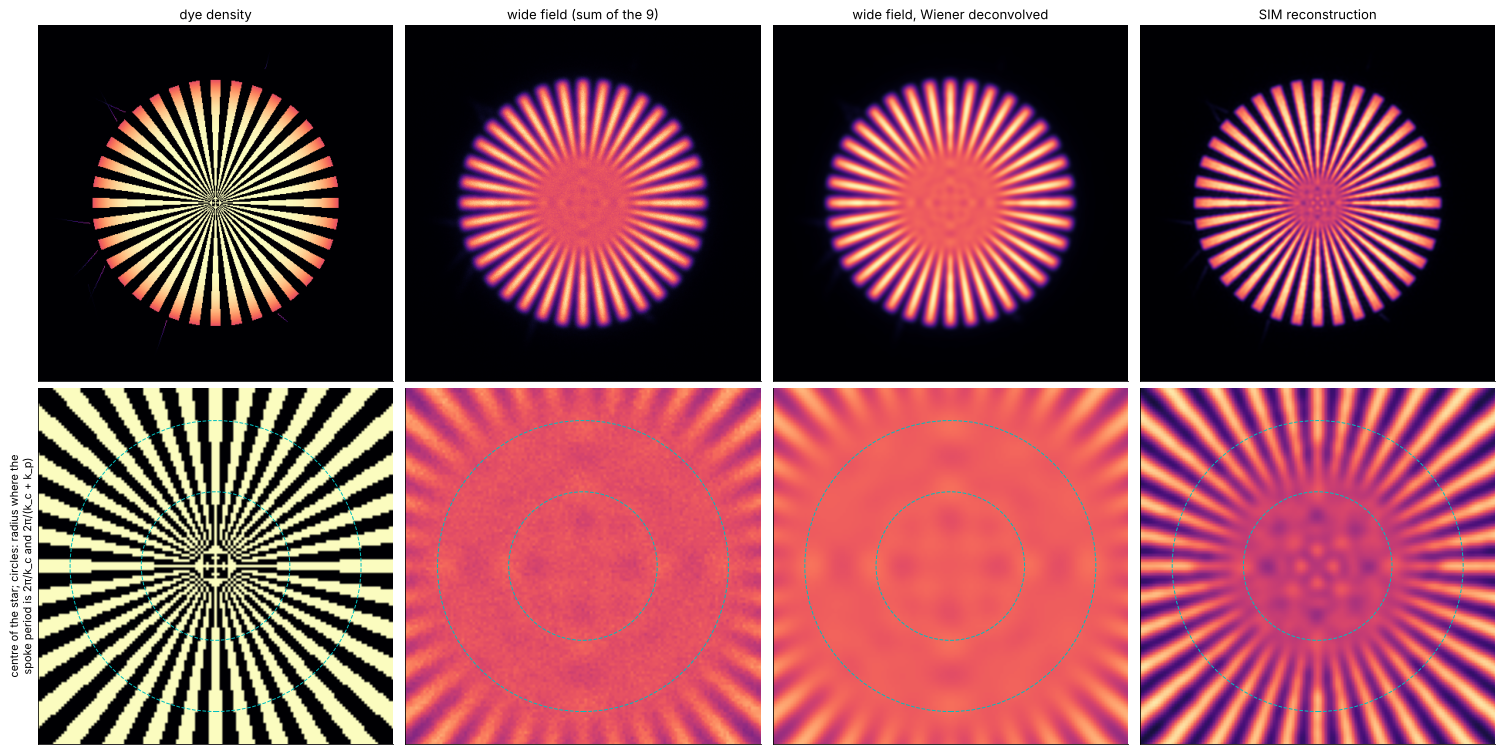

In [7]:
w = 0.08
rec, rec_spec = sr.sim_reconstruct(raw, x, y, otf, k_p, angles, phases, wiener=w)
wide = raw.sum(axis=(0, 1))
dec = sr.wiener_deconvolution(wide, otf, x, y, wiener=w)
ext = (x[0], x[-1], y[0], y[-1])
fig, axes = plt.subplots(2, 4, figsize=(21, 10.6))
imgs = ((sample, "dye density"), (wide, "wide field (sum of the 9)"),
        (dec, "wide field, Wiener deconvolved"), (rec, "SIM reconstruction"))
for col, (img, title) in enumerate(imgs):
    for row, (half, lim) in enumerate(((4.6, None), (1.3, None))):
        ax = axes[row, col]
        ax.imshow(np.clip(img, 0, None), extent=ext, cmap="magma")
        ax.set_xlim(-half, half); ax.set_ylim(-half, half)
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(title)
for ax in axes[1]:
    for r0 in (36*2*np.pi/k_c/(2*np.pi), 36*2*np.pi/(k_c + k_p)/(2*np.pi)):
        ax.add_patch(plt.Circle((0, 0), r0, fill=False, color="c", ls="--", lw=1))
axes[1, 0].set_ylabel("centre of the star; circles: radius where the\n"
                      "spoke period is 2π/k_c and 2π/(k_c + k_p)")
plt.tight_layout()

The deconvolved wide field image sharpens the filaments a bit, but the
star dissolves into grey inside the outer circle, where the spoke period
falls below $2\pi/k_c = 186$ nm. The SIM image resolves the spokes about
down to the inner circle, period $2\pi/(k_c + k_p) = 95$ nm. A
quantitative version: the modulation of the star along circles of
radius $r$ against the spoke period $2\pi r/36$.

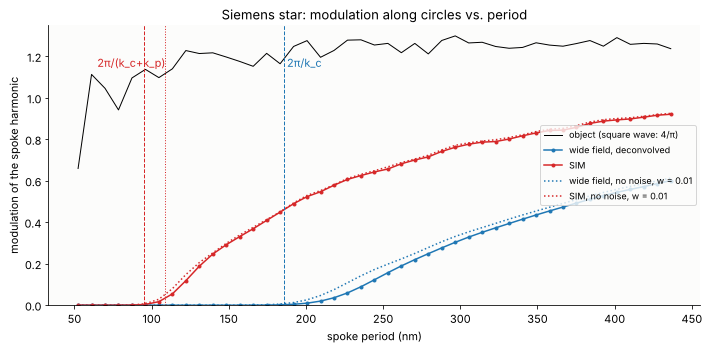

In [8]:
r_vals = np.linspace(0.3, 2.5, 45)
period = 2*np.pi*r_vals/36


def ring_contrast(img, r):
    th = np.linspace(0, 2*np.pi, 3000, endpoint=False)
    v = map_coordinates(img, [(r*np.sin(th) - y[0])/dx, (r*np.cos(th) - x[0])/dx], order=1)
    # amplitude of the spoke harmonic cos(36 phi), relative to the mean
    return 2*np.abs(np.mean(v*np.exp(-36j*th)))/np.mean(v)


rec_clean, _ = sr.sim_reconstruct(clean, x, y, otf, k_p, angles, phases, wiener=0.01)
dec_clean = sr.wiener_deconvolution(clean.sum(axis=(0, 1)), otf, x, y, wiener=0.01)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(period*1000, [ring_contrast(star*1.0, r) for r in r_vals], "k-", lw=1, label="object (square wave: 4/π)")
for img, name, style in ((dec, "wide field, deconvolved", "C0o-"), (rec, "SIM", "C3o-"),
                         (dec_clean, "wide field, no noise, w = 0.01", "C0:"),
                         (rec_clean, "SIM, no noise, w = 0.01", "C3:")):
    ax.plot(period*1000, [ring_contrast(img, r) for r in r_vals], style, ms=3, lw=1.5, label=name)
ax.axvline(2*np.pi/k_c*1000, color="C0", ls="--", lw=1)
ax.axvline(2*np.pi/(k_c + k_p)*1000, color="C3", ls="--", lw=1)
ax.axvline(2*np.pi/k_min*1000, color="C3", ls=":", lw=1)
ax.text(2*np.pi/k_c*1000 + 2, 1.15, "2π/k_c", color="C0")
ax.text(2*np.pi/(k_c + k_p)*1000 - 30, 1.15, "2π/(k_c+k_p)", color="C3")
ax.set_xlabel("spoke period (nm)"); ax.set_ylabel("modulation of the spoke harmonic")
ax.set_ylim(0, 1.35); ax.legend(fontsize=9, loc="center right")
ax.set_title("Siemens star: modulation along circles vs. period")
plt.tight_layout()

The modulation of the first harmonic of the spokes drops to zero at the
wide field cutoff, 186 nm, for the deconvolved wide field image, and
around 95 to 110 nm for SIM, between $2\pi/(k_c + k_p)$ along the
pattern directions and $2\pi/k_\mathrm{min}$ in between. The small
residual signal below the cutoffs is aliasing of the sharp star edges on
the 20 nm grid. Shot noise costs some modulation where the summed OTF is
weak, but the factor of two survives.

### What wrong parameters do

The reconstruction needs the pattern exactly: wave vector, phases and
modulation. In practice they are estimated from the raw data (the
cross-correlation of the bands, Gustafsson 2008). Three typical errors,
on the noise-free images:

- a wave vector off by $\Delta k$ (here 1 %, 0.32 rad/µm) shifts the
  bands back by the wrong amount; in real space that is a phase ramp
  $e^{i\Delta\mathbf{k}\cdot\mathbf{r}}$ on the shifted bands, so the
  error is zero in the centre of the field and grows outwards, where the
  bands drift out of step,
- phase errors of 10° leave a little of each band in the others: a weak
  texture at the pattern frequency,
- a modulation entered too low (0.6 instead of 1) scales the shifted
  bands up by 1/0.6: the high frequencies are over-weighted and the fine
  spokes get too much contrast.

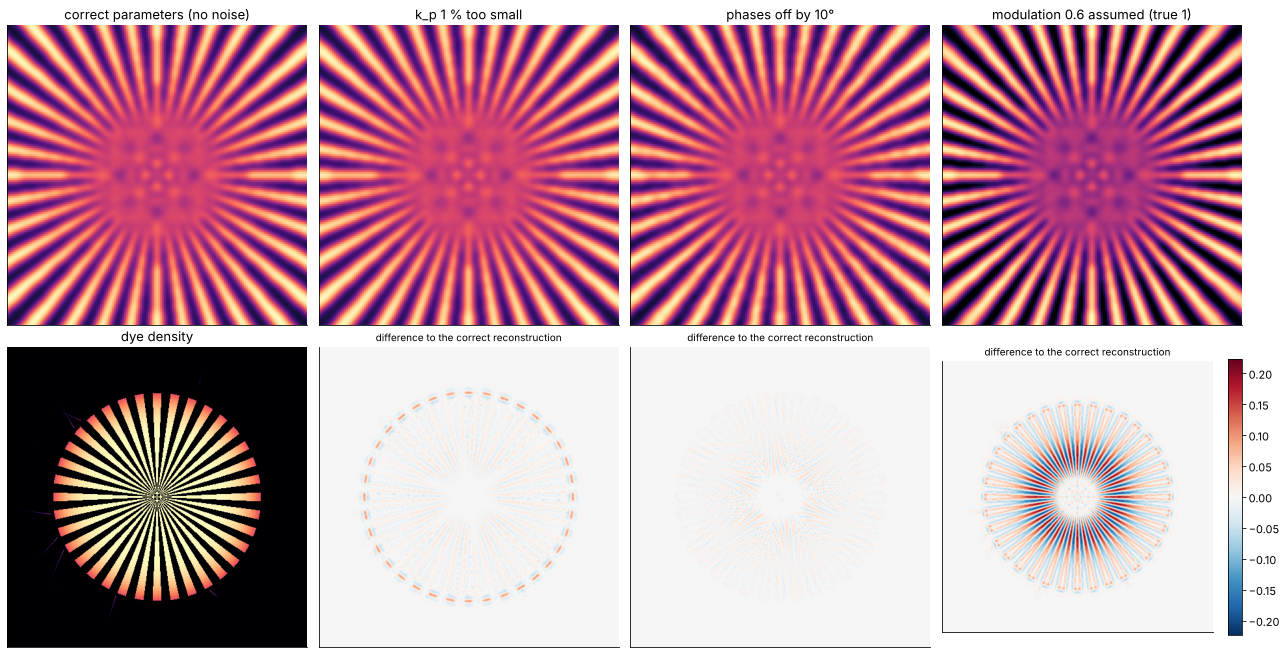

In [9]:
cases = (("k_p 1 % too small", dict(k=k_p/1.01)),
         ("phases off by 10°", dict(ph=phases + np.deg2rad([0, 10, -10]))),
         ("modulation 0.6 assumed (true 1)", dict(m=0.6)))
fig, axes = plt.subplots(2, 4, figsize=(18, 9.2))
axes[0, 0].imshow(np.clip(rec_clean, 0, None), extent=ext, cmap="magma")
axes[0, 0].set_title("correct parameters (no noise)")
axes[1, 0].imshow(sample, extent=ext, cmap="magma")
axes[1, 0].set_title("dye density")
vmax = 0.25*rec_clean.max()
for col, (title, kw) in enumerate(cases, start=1):
    bad, _ = sr.sim_reconstruct(clean, x, y, otf, kw.get("k", k_p), angles, kw.get("ph", phases),
                                modulation=kw.get("m", 1.0), wiener=0.01)
    axes[0, col].imshow(np.clip(bad, 0, None), extent=ext, cmap="magma")
    axes[0, col].set_title(title)
    im = axes[1, col].imshow(bad - rec_clean, extent=ext, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[1, col].set_title("difference to the correct reconstruction", fontsize=10)
plt.colorbar(im, ax=axes[1, 3], fraction=0.046)
for ax in axes[0]:
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
for ax in axes[1]:
    ax.set_xlim(-4.6, 4.6); ax.set_ylim(-4.6, 4.6)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

None of these is dramatic at this size, but all are systematic and
survive averaging. The wave vector error matters most for large fields:
the bands are out of phase by $\pi$ at $r = \pi/\Delta k$, 10 µm here,
so a camera field of 50 µm needs $k_p$ to about 0.1 %.

## 2. STED: depletion with a doughnut

### The setup

An excitation pulse (here 640 nm) brings the fluorophores into the
excited state, and a red-shifted depletion pulse (775 nm) right after it
forces them back by stimulated emission before they fluoresce. A vortex
phase plate $e^{i\varphi}$ and a quarter wave plate give the depletion
beam a doughnut-shaped focus with a zero in the centre. A molecule
survives the depletion with the probability $\eta = \exp(-\ln 2\,
I_\mathrm{STED}/I_s)$, where $I_s$ is the intensity that halves the
fluorescence, so the effective PSF is

$$h_\mathrm{eff}(\mathbf{r}) = h_\mathrm{exc}(\mathbf{r})\,
  \exp\!\big(-\ln 2\;\zeta\, I_\mathrm{STED}(\mathbf{r})/I_\mathrm{max}\big),
  \qquad \zeta = I_\mathrm{max}/I_s .$$

The spot is scanned over the sample, as in the confocal microscope of
notebook 54.

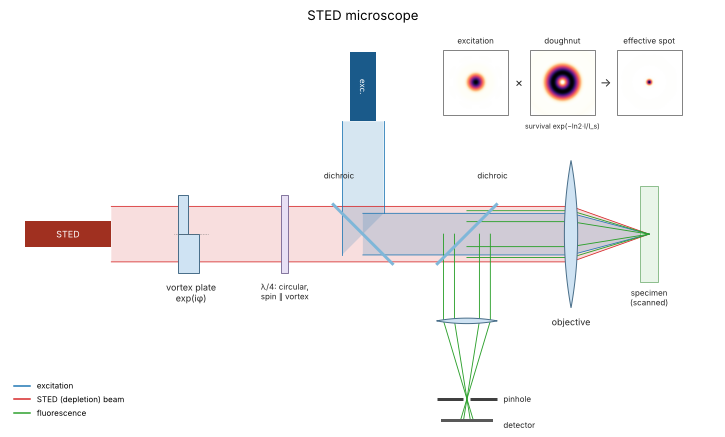

In [10]:
n_foc, L_foc = 1024, 10.0       # 9.8 nm sampling in the focal plane
xf, yf, Xf, Yf = grid2d(-L_foc/2, L_foc/2, -L_foc/2, L_foc/2, n_foc)
dxf = xf[1] - xf[0]
c = n_foc//2
wl_ex2, wl_sted = 0.640, 0.775
E_exc = sr.vortex_focus(xf, yf, wl_ex2, NA, n=n_oil, charge=0, jones=(1, 1j))
I_exc = np.sum(np.abs(E_exc)**2, -1)
I_exc /= I_exc.max()
pols = {"circular, spin parallel (1, i)": (1, 1j), "circular, spin antiparallel (1, −i)": (1, -1j),
        "linear x": (1, 0)}
E_sted = {name: sr.vortex_focus(xf, yf, wl_sted, NA, n=n_oil, charge=1, jones=j)
          for name, j in pols.items()}
I_sted = {name: np.sum(np.abs(E)**2, -1)/np.sum(np.abs(E)**2, -1).max() for name, E in E_sted.items()}
good = "circular, spin parallel (1, i)"
show = lambda I: I[c - 80:c + 80, c - 80:c + 80]
fig, ax = plt.subplots(figsize=(12, 6.2))
sketch.sted_microscope(ax, images=(show(I_exc), show(I_sted[good]),
                                   show(sr.sted_psf(I_exc, I_sted[good], 10.0))),
                       title="STED microscope")
plt.tight_layout()

### The doughnut and its polarization

At NA 1.4 the focus is strongly vectorial (notebook 02). Write the
circular pupil polarization as $\hat x + i\sigma\hat y =
e^{i\sigma\varphi}(\hat\rho + i\sigma\hat\varphi)$ with the spin
$\sigma = \pm1$. The aplanatic lens tilts the radial part,
$\hat\rho \to \cos\theta\,\hat\rho - \sin\theta\,\hat z$, so with the
vortex $e^{il\varphi}$ the longitudinal field carries
$e^{i(l + \sigma)\varphi}$ and becomes $\propto J_{l+\sigma}$ in the
focus, while the transverse components carry $e^{il\varphi}$ and
$e^{i(l+2\sigma)\varphi}$. On the axis only an azimuthal order of zero
survives:

- $l = 1$, $\sigma = +1$ (spin parallel to the orbital angular
  momentum): orders 1, 3 (transverse) and 2 ($E_z$), a **true zero**,
- $l = 1$, $\sigma = -1$: $E_z \propto J_0$ fills the centre,
- linear polarization is half of each.

The topological charge of $E_z$ around the centre (`vortices.topological_charge()`)
and the intensity left in the centre confirm this.

circular, spin parallel (1, i)       centre intensity / peak = 3.06e-06
circular, spin antiparallel (1, −i)  centre intensity / peak = 8.85e-01
linear x                             centre intensity / peak = 3.91e-01


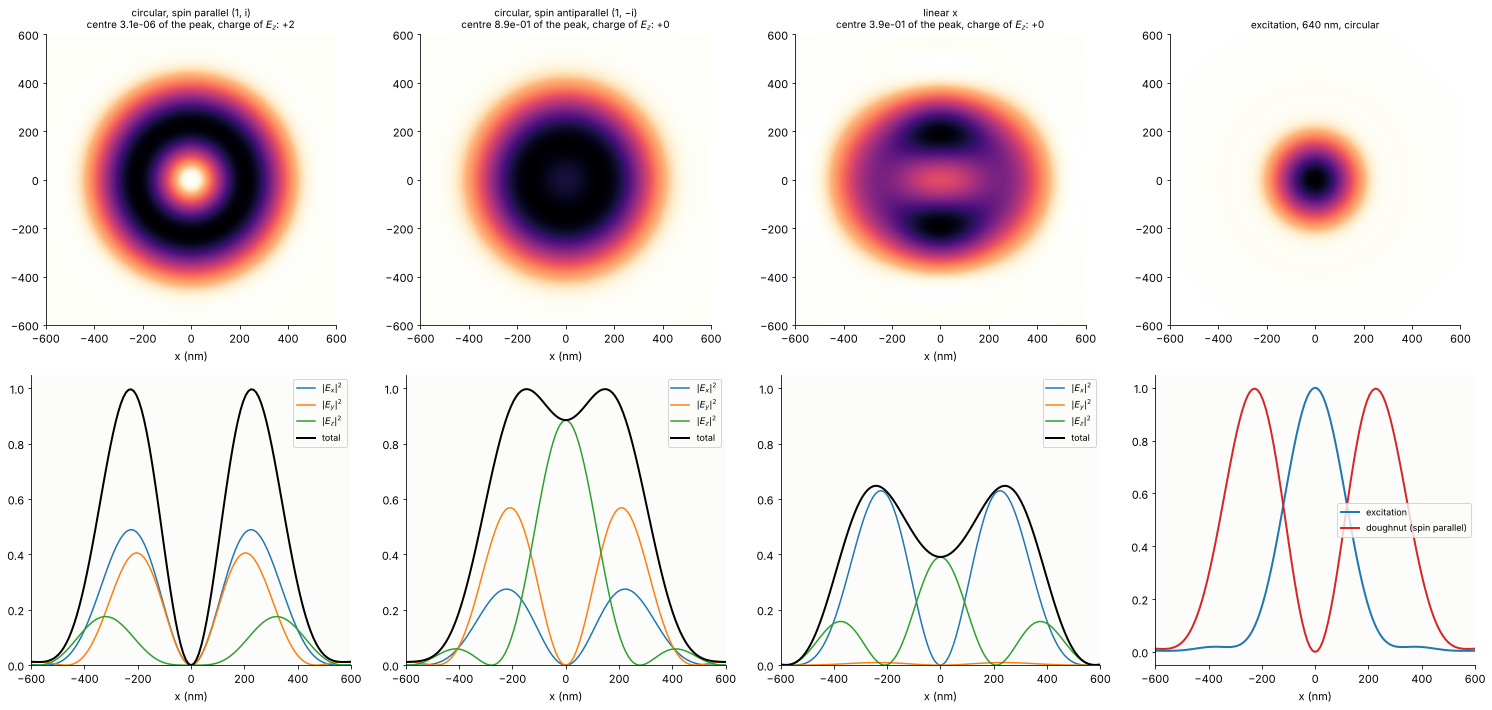

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(21, 10))
names = list(pols)
ext_f = (xf[0]*1000, xf[-1]*1000, yf[0]*1000, yf[-1]*1000)
for col, name in enumerate(names):
    E = E_sted[name]
    I = np.sum(np.abs(E)**2, -1)
    ax = axes[0, col]
    ax.imshow(I/I.max(), extent=ext_f, cmap=LIGHT, vmin=0, vmax=1)
    ax.set_xlim(-600, 600); ax.set_ylim(-600, 600)
    q = vortices.topological_charge(E[:, :, 2], xf, yf, 0.15)
    ax.set_title(f"{name}\ncentre {I[c, c]/I.max():.1e} of the peak, charge of $E_z$: {int(round(q)) + 0:+d}",
                 fontsize=10)
    ax.set_xlabel("x (nm)")
    ax = axes[1, col]
    for i, comp in enumerate(("$|E_x|^2$", "$|E_y|^2$", "$|E_z|^2$")):
        ax.plot(xf*1000, np.abs(E[c, :, i])**2/I.max(), lw=1.5, label=comp)
    ax.plot(xf*1000, I[c]/I.max(), "k", lw=2, label="total")
    ax.set_xlim(-600, 600); ax.set_ylim(0, 1.05); ax.set_xlabel("x (nm)")
    ax.legend(fontsize=9)
ax = axes[0, 3]
ax.imshow(I_exc, extent=ext_f, cmap=LIGHT)
ax.set_xlim(-600, 600); ax.set_ylim(-600, 600)
ax.set_title(f"excitation, {wl_ex2*1000:.0f} nm, circular", fontsize=10)
ax = axes[1, 3]
ax.plot(xf*1000, I_exc[c], "C0", lw=2, label="excitation")
ax.plot(xf*1000, I_sted[good][c], "C3", lw=2, label="doughnut (spin parallel)")
ax.set_xlim(-600, 600); ax.set_xlabel("x (nm)"); ax.legend(fontsize=9)
plt.tight_layout()
for name in names:
    print(f"{name:36s} centre intensity / peak = {I_sted[name][c, c]:.2e}")

With the wrong handedness the longitudinal field puts 88 % of the peak
intensity into the centre of the "doughnut", and linear polarization 39 %:
useless for STED. The parallel case leaves $3\cdot10^{-6}$, the discrete
sampling of the helical phase on the pupil grid. (At low NA the
longitudinal field is weak and all three would look alike.)

### Effective PSF against saturation

Near the zero the doughnut is parabolic, $I_\mathrm{STED}/I_\mathrm{max}
\approx \beta r^2$, and the excitation core is close to a Gaussian of
FWHM $d_0$, $\exp(-4\ln2\,r^2/d_0^2)$. The product is again a Gaussian,
with

$$d = \frac{d_0}{\sqrt{1 + \zeta\beta d_0^2/4}} .$$

This is the square root law; the textbook form $d \approx
\lambda/(2\mathrm{NA}\sqrt{1 + \zeta})$ (`sted_fwhm()`) assumes $d_0 =
\lambda/(2\mathrm{NA})$ and $\beta d_0^2/4 = 1$, i.e. a doughnut that
rises to its maximum within about one excitation radius. The curvature
$\beta$ is fitted to the computed doughnut within 40 nm of the centre.

excitation FWHM d0 = 259 nm (λ/2NA = 229 nm), doughnut curvature β = 49.1 /µm², β d0²/4 = 0.82


ζ =    0: FWHM 258.7 nm, parabolic model 258.7 nm, textbook 228.6 nm
ζ =    1: FWHM 199.4 nm, parabolic model 191.7 nm, textbook 161.6 nm
ζ =    2: FWHM 165.1 nm, parabolic model 159.2 nm, textbook 132.0 nm
ζ =    5: FWHM 116.8 nm, parabolic model 114.5 nm, textbook  93.3 nm
ζ =   10: FWHM  86.2 nm, parabolic model  85.2 nm, textbook  68.9 nm
ζ =   20: FWHM  62.2 nm, parabolic model  62.0 nm, textbook  49.9 nm
ζ =   50: FWHM  39.8 nm, parabolic model  39.9 nm, textbook  32.0 nm
ζ =  100: FWHM  28.9 nm, parabolic model  28.4 nm, textbook  22.7 nm
ζ =  200: FWHM  20.2 nm, parabolic model  20.1 nm, textbook  16.1 nm


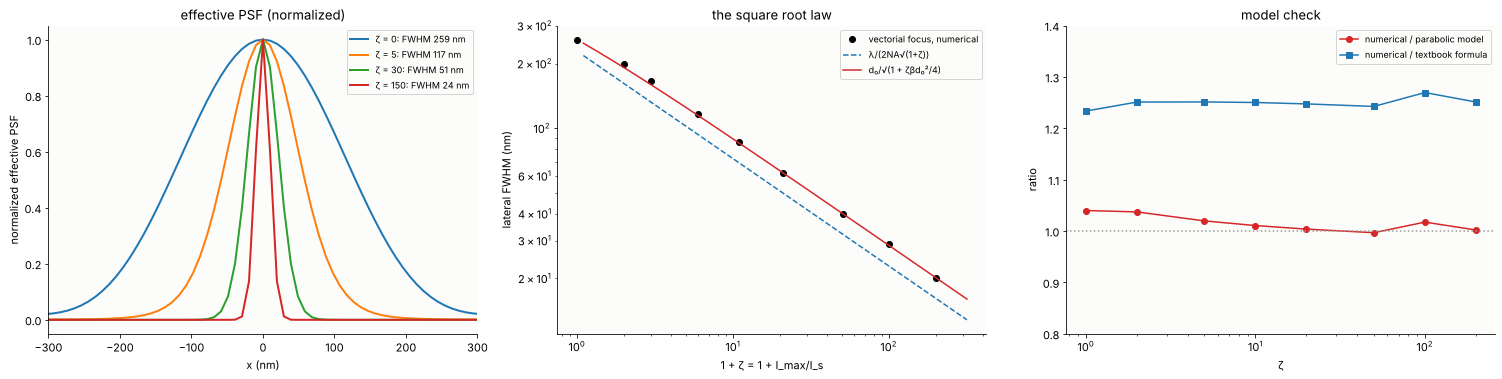

In [12]:
r_fit = np.hypot(Xf, Yf)
sel = (r_fit > 0) & (r_fit < 0.04)
beta = np.sum(I_sted[good][sel]*r_fit[sel]**2)/np.sum(r_fit[sel]**4)
d0 = fwhm(xf, I_exc[c])
print(f"excitation FWHM d0 = {d0*1000:.0f} nm (λ/2NA = {wl_ex2/(2*NA)*1000:.0f} nm), "
      f"doughnut curvature β = {beta:.1f} /µm², β d0²/4 = {beta*d0**2/4:.2f}")
zetas = np.array([0, 1, 2, 5, 10, 20, 50, 100, 200])
d_num = np.array([0.5*(fwhm(xf, sr.sted_psf(I_exc, I_sted[good], z)[c]) +
                       fwhm(yf, sr.sted_psf(I_exc, I_sted[good], z)[:, c])) for z in zetas])
zz = np.logspace(-1, 2.5, 200)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.4))
ax = axes[0]
for z in (0, 5, 30, 150):
    h = sr.sted_psf(I_exc, I_sted[good], z)
    ax.plot(xf*1000, h[c]/h.max(), lw=2, label=f"ζ = {z}: FWHM {fwhm(xf, h[c])*1000:.0f} nm")
ax.set_xlim(-300, 300); ax.set_xlabel("x (nm)"); ax.set_ylabel("normalized effective PSF")
ax.legend(fontsize=9); ax.set_title("effective PSF (normalized)")
ax = axes[1]
ax.loglog(1 + zetas, d_num*1000, "ko", label="vectorial focus, numerical")
ax.loglog(1 + zz, sr.sted_fwhm(wl_ex2, NA, zz)*1000, "C0--", label="λ/(2NA√(1+ζ))")
ax.loglog(1 + zz, d0/np.sqrt(1 + zz*beta*d0**2/4)*1000, "C3-", label="d₀/√(1 + ζβd₀²/4)")
ax.set_xlabel("1 + ζ = 1 + I_max/I_s"); ax.set_ylabel("lateral FWHM (nm)"); ax.legend(fontsize=9)
ax.set_title("the square root law")
ax = axes[2]
ax.semilogx(zetas[1:], d_num[1:]/(d0/np.sqrt(1 + zetas[1:]*beta*d0**2/4)), "C3o-",
            label="numerical / parabolic model")
ax.semilogx(zetas[1:], d_num[1:]/sr.sted_fwhm(wl_ex2, NA, zetas[1:]), "C0s-",
            label="numerical / textbook formula")
ax.axhline(1, color="0.6", ls=":")
ax.set_xlabel("ζ"); ax.set_ylabel("ratio"); ax.legend(fontsize=9); ax.set_ylim(0.8, 1.4)
ax.set_title("model check")
plt.tight_layout()
for z, d in zip(zetas, d_num):
    print(f"ζ = {z:4.0f}: FWHM {d*1000:5.1f} nm, parabolic model "
          f"{d0/np.sqrt(1 + z*beta*d0**2/4)*1000:5.1f} nm, textbook {sr.sted_fwhm(wl_ex2, NA, z)*1000:5.1f} nm")

The effective spot follows the square root law over the whole range: 30
nm at $\zeta = 100$, a tenth of the confocal spot. The parabolic model
with the actual doughnut curvature is within a few percent once $\zeta
\gtrsim 5$, when the spot sits deep in the parabolic core. The textbook
formula has the right scaling but is about 25 % optimistic here: the real
excitation spot (259 nm) is wider than $\lambda/(2\mathrm{NA}) = 229$ nm,
and $\beta d_0^2/4 = 0.82$ instead of 1. At low $\zeta$ the depletion also cuts into the
side lobes and flanks, beyond the parabolic approximation.

### An imperfect zero

Whatever intensity $I_0$ remains in the centre depletes the wanted
fluorescence too: the peak signal falls like $\exp(-\ln2\,\zeta
I_0/I_\mathrm{max})$. With $10^{-6}$ this does not matter, with a few
percent (a slightly wrong wave plate, aberrations, a misaligned plate) the
signal is gone long before the resolution is interesting.

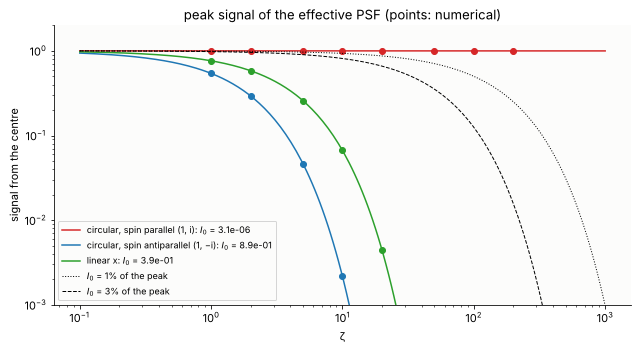

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
zz = np.logspace(-1, 3, 200)
for name, col in zip(names, ("C3", "C0", "C2")):
    c0 = I_sted[name][c, c]
    peak = [sr.sted_psf(I_exc, I_sted[name], z)[c, c] for z in zetas[1:]]
    ax.loglog(zetas[1:], peak, "o", color=col)
    ax.loglog(zz, np.exp(-np.log(2)*zz*c0), "-", color=col, lw=1.5,
              label=f"{name}: $I_0$ = {c0:.1e}")
for c0, ls in ((0.01, ":"), (0.03, "--")):
    ax.loglog(zz, np.exp(-np.log(2)*zz*c0), "k", ls=ls, lw=1, label=f"$I_0$ = {c0:.0%} of the peak")
ax.set_ylim(1e-3, 2); ax.set_xlabel("ζ"); ax.set_ylabel("signal from the centre")
ax.legend(fontsize=9); ax.set_title("peak signal of the effective PSF (points: numerical)")
plt.tight_layout()

### A STED image

A test object of dye molecules: pairs of points 150, 80 and 50 nm apart
and a ring of 120 nm diameter, imaged with the bare excitation spot
(confocal with a large pinhole) and with $\zeta = 20$ and $100$.

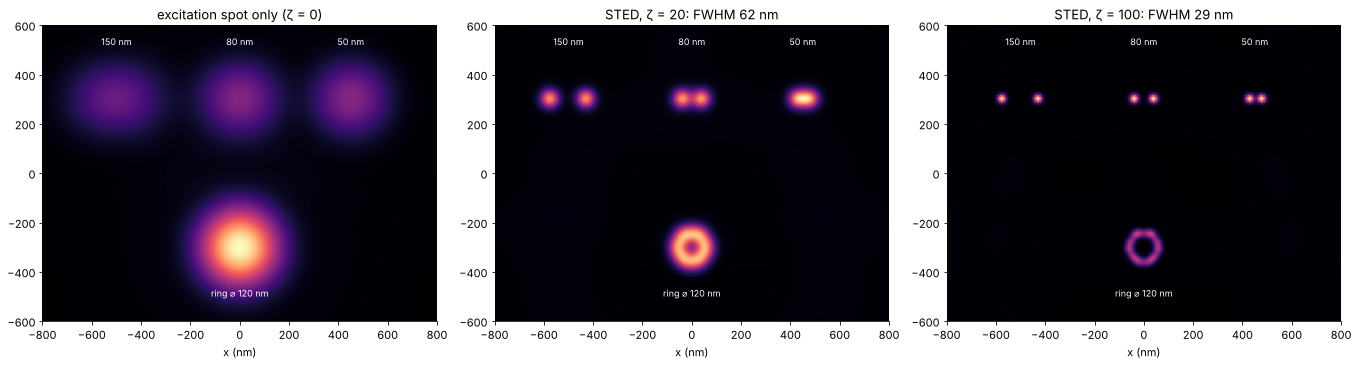

In [14]:
obj = np.zeros_like(Xf)
def put(px, py, val=1.0):
    obj[int(round(py/dxf)) + c, int(round(px/dxf)) + c] += val
for (x0, sep) in ((-0.5, 0.15), (0.0, 0.08), (0.45, 0.05)):
    put(x0 - sep/2, 0.3); put(x0 + sep/2, 0.3)
for t in np.linspace(0, 2*np.pi, 24, endpoint=False):
    put(0.06*np.cos(t), -0.3 + 0.06*np.sin(t), 0.25)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, z in zip(axes, (0, 20, 100)):
    h = sr.sted_psf(I_exc, I_sted[good], z)
    img = np.real(np.fft.fftshift(np.fft.ifft2(np.fft.fft2(np.fft.ifftshift(obj))*np.fft.fft2(np.fft.ifftshift(h)))))
    ax.imshow(img, extent=ext_f, cmap="magma")
    ax.set_xlim(-800, 800); ax.set_ylim(-600, 600); ax.set_xlabel("x (nm)")
    ax.set_title("excitation spot only (ζ = 0)" if z == 0 else
                 f"STED, ζ = {z}: FWHM {fwhm(xf, h[c])*1000:.0f} nm")
for ax in axes:
    for x0, sep in ((-0.5, 0.15), (0.0, 0.08), (0.45, 0.05)):
        ax.text(x0*1000, 520, f"{sep*1000:.0f} nm", color="w", ha="center", fontsize=9)
    ax.text(0, -500, "ring ⌀ 120 nm", color="w", ha="center", fontsize=9)
plt.tight_layout()

## 3. Localization microscopy (PALM/STORM)

### Precision against photons, pixels and background

Photoswitchable dyes are kept dark most of the time; in each camera frame
only a sparse random subset lights up, so every spot is one molecule and
can be fitted. Notebook 18 showed that the centroid of a Gaussian spot of
width $\sigma$ with $N$ photons scatters by $\sigma/\sqrt{N}$. A camera
adds two things: pixels of size $a$ (the effective width becomes
$\sigma_a^2 = \sigma^2 + a^2/12$) and a background of $b$ photons per
pixel. Mortensen et al. (2010) give

$$\mathrm{var}_\mathrm{LSQ} = \frac{\sigma_a^2}{N}\Big(\frac{16}{9} +
  \frac{8\pi\sigma_a^2 b}{Na^2}\Big),\qquad
  \mathrm{var}_\mathrm{MLE} = \frac{\sigma_a^2}{N}\Big(1 + \int_0^1
  \frac{\ln t\,dt}{1 + Na^2t/(2\pi\sigma_a^2 b)}\Big)^{-1}$$

for an unweighted least squares fit and the Poisson maximum likelihood
fit; the latter reaches the Cramér-Rao bound. The PSF width: a Gaussian
fitted to the Airy pattern has $\sigma \approx 0.21\lambda/\mathrm{NA}$,
100 nm for a red dye (670 nm) at NA 1.4; the camera pixel is 100 nm in
the sample. Each point below is the scatter of 300 simulated spots at
random subpixel positions.

b =  0, N = 1000: MLE 3.2 nm (Mortensen 3.3), LSQ 4.3 nm (Mortensen 4.4), centroid 3.2 nm
b = 10, N = 1000: MLE 4.1 nm (Mortensen 4.1), LSQ 4.8 nm (Mortensen 4.7), centroid 15.7 nm


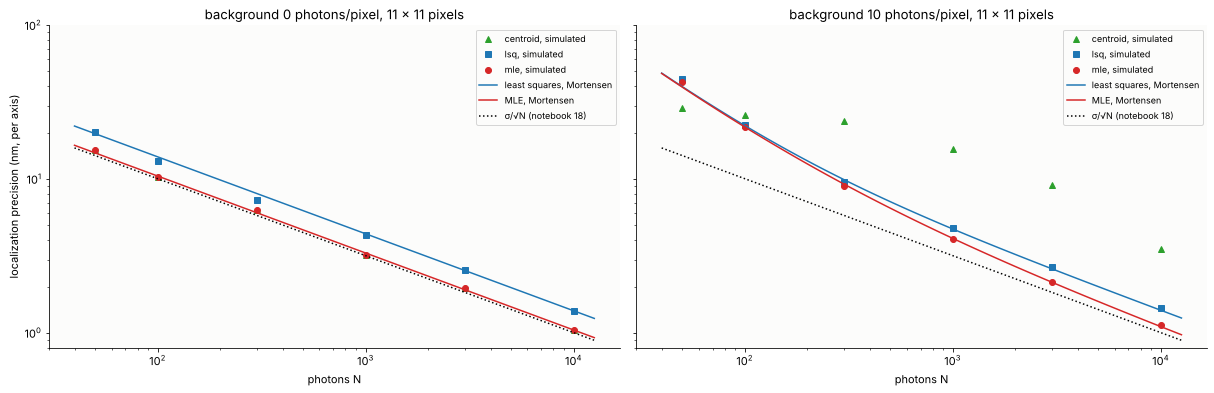

In [15]:
sigma_psf = 0.21*0.670/NA
a_pix = 0.1
xs = (np.arange(11) - 5)*a_pix
rng = np.random.default_rng(11)
N_list = np.array([50, 100, 300, 1000, 3000, 10000])
results = {}
for b in (0.0, 10.0):
    for m in ("centroid", "lsq", "mle"):
        results[b, m] = []
    for Nph in N_list:
        err = {m: [] for m in ("centroid", "lsq", "mle")}
        for _ in range(300):
            x0, y0 = rng.uniform(-a_pix/2, a_pix/2, 2)
            img = rng.poisson(sr.gaussian_spot(xs, xs, x0, y0, sigma_psf, Nph, b))
            for m in err:
                ex, ey = sr.localize(img, xs, xs, sigma_psf, m)
                err[m].append(ex - x0)
        for m in err:
            results[b, m].append(np.std(err[m]))
NN = np.logspace(1.6, 4.1, 100)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.6), sharey=True)
for ax, b in zip(axes, (0.0, 10.0)):
    for m, col, mk in (("centroid", "C2", "^"), ("lsq", "C0", "s"), ("mle", "C3", "o")):
        ax.loglog(N_list, np.array(results[b, m])*1000, mk, color=col, label=f"{m}, simulated")
    ax.loglog(NN, sr.localization_precision(sigma_psf, NN, a_pix, b, "lsq")*1000, "C0-",
              label="least squares, Mortensen")
    ax.loglog(NN, sr.localization_precision(sigma_psf, NN, a_pix, b, "mle")*1000, "C3-",
              label="MLE, Mortensen")
    ax.loglog(NN, sigma_psf/np.sqrt(NN)*1000, "k:", label="σ/√N (notebook 18)")
    ax.set_xlabel("photons N"); ax.set_title(f"background {b:.0f} photons/pixel, 11 × 11 pixels")
    ax.legend(fontsize=9)
axes[0].set_ylabel("localization precision (nm, per axis)")
axes[0].set_ylim(0.8, 100)
plt.tight_layout()
for b in (0.0, 10.0):
    i = list(N_list).index(1000)
    print(f"b = {b:2.0f}, N = 1000: MLE {results[b, 'mle'][i]*1000:.1f} nm "
          f"(Mortensen {sr.localization_precision(sigma_psf, 1000, a_pix, b)*1000:.1f}), "
          f"LSQ {results[b, 'lsq'][i]*1000:.1f} nm "
          f"(Mortensen {sr.localization_precision(sigma_psf, 1000, a_pix, b, 'lsq')*1000:.1f}), "
          f"centroid {results[b, 'centroid'][i]*1000:.1f} nm")

Without background the MLE (and here also the centroid) reaches
$\sigma_a/\sqrt{N}$, slightly above $\sigma/\sqrt{N}$ because of the
pixels; the unweighted least squares fit is $4/3$ worse, as Mortensen's
$16/9$ predicts. A background of 10 photons per pixel, typical for a
cell, hurts at low $N$ and ruins the plain centroid at every $N$ (the
background pulls it towards the window centre), while both fits model
it. A thousand photons, a typical switching event of a good dye, give
about 4 nm.

### A PALM image

The test structure: two parallel lines 40 nm apart and a ring of 100 nm
radius, densely labelled. Each localization comes from one switching
event with an exponentially distributed photon number (mean 800) on a
background of 10 photons per pixel, fitted by MLE; events with fewer than
150 photons are discarded. The image is the histogram of the positions
with 5 nm bins.

3298 localizations, rms error 7.1 nm per axis, rms of the predicted precisions 6.9 nm


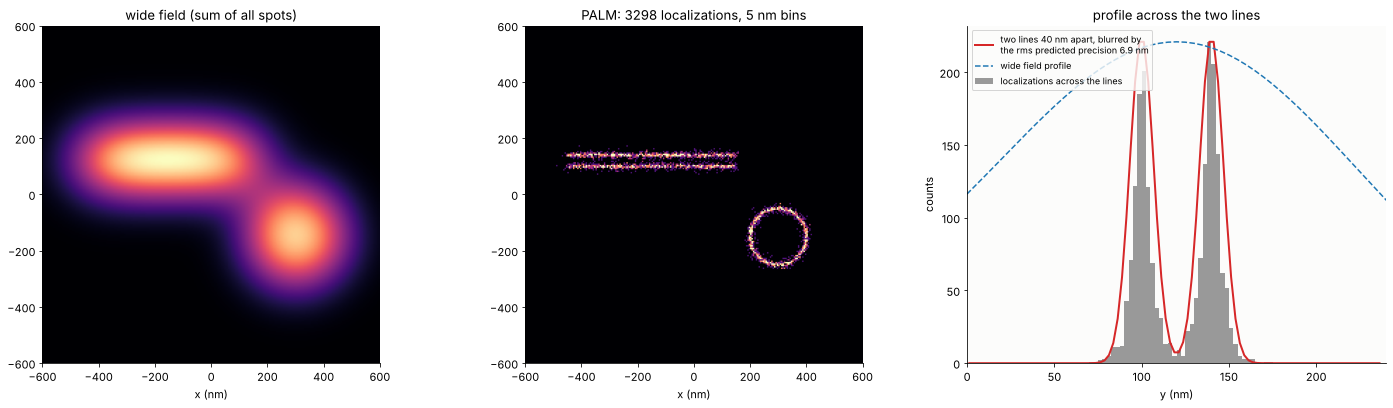

In [16]:
n_events = 4000
rng = np.random.default_rng(5)
kind = rng.random(n_events)
true = np.empty((n_events, 2))
lines = kind < 0.6
true[lines, 0] = rng.uniform(-0.45, 0.15, lines.sum())
true[lines, 1] = 0.12 + np.where(rng.random(lines.sum()) < 0.5, -0.02, 0.02)
phi = rng.uniform(0, 2*np.pi, (~lines).sum())
true[~lines] = np.c_[0.3 + 0.1*np.cos(phi), -0.15 + 0.1*np.sin(phi)]
photons = rng.exponential(800, n_events)
keep = photons > 150
locs, prec = [], []
for (x0, y0), Nph in zip(true[keep], photons[keep]):
    # an 11 x 11 pixel window around the pixel nearest to the molecule
    xc, yc = np.round(x0/a_pix)*a_pix, np.round(y0/a_pix)*a_pix
    img = rng.poisson(sr.gaussian_spot(xs + xc, xs + yc, x0, y0, sigma_psf, Nph, 10.0))
    locs.append(sr.localize(img, xs + xc, xs + yc, sigma_psf, "mle"))
    prec.append(sr.localization_precision(sigma_psf, Nph, a_pix, 10.0))
locs, prec = np.array(locs), np.array(prec)
err = locs - true[keep]
print(f"{keep.sum()} localizations, rms error {np.sqrt(np.mean(err**2, axis=0)).mean()*1000:.1f} nm "
      f"per axis, rms of the predicted precisions {np.sqrt(np.mean(prec**2))*1000:.1f} nm")

bins = np.arange(-0.6, 0.6 + 1e-9, 0.005)
hist, _, _ = np.histogram2d(locs[:, 1], locs[:, 0], bins=(bins, bins))
# the wide field image of the same molecules: each one's photons in its Gaussian spot
wf_x = np.arange(-0.6, 0.6, 0.005)
WX, WY = np.meshgrid(wf_x, wf_x)
wf_img = np.zeros_like(WX)
for (x0, y0), Nph in zip(true[keep], photons[keep]):
    wf_img += Nph*np.exp(-((WX - x0)**2 + (WY - y0)**2)/(2*sigma_psf**2))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
axes[0].imshow(wf_img, extent=(-600, 600, -600, 600), cmap="magma")
axes[0].set_title("wide field (sum of all spots)")
axes[1].imshow(hist, extent=(-600, 600, -600, 600), cmap="magma", vmax=np.percentile(hist, 99.7))
axes[1].set_title(f"PALM: {len(locs)} localizations, 5 nm bins")
for ax in axes[:2]:
    ax.set_xlabel("x (nm)")
ax = axes[2]
sel_l = (locs[:, 0] > -0.45) & (locs[:, 0] < 0.15)
yy = np.arange(0.0, 0.24, 0.0025)
cnt, _ = np.histogram(locs[sel_l, 1], bins=yy)
yc_ = (yy[1:] + yy[:-1])/2
ax.bar(yc_*1000, cnt, width=2.5, color="0.6", label="localizations across the lines")
s_mix = np.sqrt(np.mean(prec**2))
model = sum(np.exp(-(yc_ - y0)**2/(2*s_mix**2)) for y0 in (0.10, 0.14))
ax.plot(yc_*1000, model/model.max()*cnt.max(), "C3", lw=2,
        label=f"two lines 40 nm apart, blurred by\nthe rms predicted precision {s_mix*1000:.1f} nm")
wf_prof = wf_img[:, (wf_x > -0.45) & (wf_x < 0.15)].sum(axis=1)
ax.plot(wf_x*1000, wf_prof/wf_prof.max()*cnt.max(), "C0--", lw=1.5, label="wide field profile")
ax.set_xlim(0, 240); ax.set_xlabel("y (nm)"); ax.set_ylabel("counts"); ax.legend(fontsize=9, loc="upper left")
ax.set_title("profile across the two lines")
plt.tight_layout()

The wide field image shows one blurred line and a blob; the PALM image
separates the two lines 40 nm apart and shows the ring as a ring. The
profile across the lines is the true structure blurred by the
localization precision predicted by `localization_precision()` (the rms
over all events). The price is time: thousands of camera frames, each
with only a few active molecules, and a resolution that also depends on
the labelling density (Nyquist: at least two labels per resolution
length) and the size of the label itself.

## Summary

- **SIM** mixes object frequencies into the OTF with a sinusoidal
  excitation. Three phases per angle separate the three bands
  (`sim_bands()`, exact to rounding), the shifted bands extend the support
  to $k_c + k_p$, a rounded hexagon with the inscribed radius
  $k_p\cos30° + \sqrt{k_c^2 - k_p^2/4}$ for three angles (1.70 $k_c$
  here, as computed). The Siemens star is resolved down to about 100 nm
  against 186 nm in wide field, with noise and a Wiener filter. Wrong
  pattern parameters give systematic errors that grow with the field
  size (wave vector) or distort the contrast (modulation).
- **STED** needs a true zero: with a vortex of charge +1 the circular
  polarization must have its spin parallel to the orbital angular
  momentum; the other handedness leaves 88 % of the peak in the centre at
  NA 1.4 through the longitudinal field. The effective PSF follows the
  square root law, $d_0/\sqrt{1 + \zeta\beta d_0^2/4}$ with the doughnut
  curvature $\beta$; $\lambda/(2\mathrm{NA}\sqrt{1 + \zeta})$ has the
  right scaling and is 25 % optimistic. A residual centre intensity $I_0$
  costs the factor $\exp(-\ln2\,\zeta I_0/I_\mathrm{max})$ in signal.
- **Localization** reaches $\sigma_a/\sqrt{N}$ with a maximum likelihood
  fit, in agreement with Mortensen's formulas including background; least
  squares is 4/3 worse, and the plain centroid breaks down with
  background. A PALM image resolves lines 40 nm apart.

In [17]:
print(f"run time {time.time() - t_start:.0f} s")

run time 39 s


## References

- M. G. L. Gustafsson, "Surpassing the lateral resolution limit by a factor of two using structured illumination microscopy", J. Microsc. 198, 82-87 (2000).
- R. Heintzmann and C. Cremer, "Laterally modulated excitation microscopy: improvement of resolution by using a diffraction grating", Proc. SPIE 3568, 185-196 (1999).
- M. G. L. Gustafsson, L. Shao, P. M. Carlton, C. J. R. Wang, I. N. Golubovskaya, W. Z. Cande, D. A. Agard and J. W. Sedat, "Three-dimensional resolution doubling in wide-field fluorescence microscopy by structured illumination", Biophys. J. 94, 4957-4970 (2008).
- S. W. Hell and J. Wichmann, "Breaking the diffraction resolution limit by stimulated emission: stimulated-emission-depletion fluorescence microscopy", Opt. Lett. 19, 780-782 (1994).
- T. A. Klar, S. Jakobs, M. Dyba, A. Egner and S. W. Hell, "Fluorescence microscopy with diffraction resolution barrier broken by stimulated emission", PNAS 97, 8206-8210 (2000).
- B. Harke, J. Keller, C. K. Ullal, V. Westphal, A. Schönle and S. W. Hell, "Resolution scaling in STED microscopy", Opt. Express 16, 4154-4162 (2008).
- D. Wildanger, R. Medda, L. Kastrup and S. W. Hell, "A compact STED microscope providing 3D nanoscale resolution", J. Microsc. 236, 35-43 (2009).
- B. Richards and E. Wolf, "Electromagnetic diffraction in optical systems II. Structure of the image field in an aplanatic system", Proc. R. Soc. Lond. A 253, 358-379 (1959).
- E. Betzig, G. H. Patterson, R. Sougrat, O. W. Lindwasser, S. Olenych, J. S. Bonifacino, M. W. Davidson, J. Lippincott-Schwartz and H. F. Hess, "Imaging intracellular fluorescent proteins at nanometer resolution", Science 313, 1642-1645 (2006).
- M. J. Rust, M. Bates and X. Zhuang, "Sub-diffraction-limit imaging by stochastic optical reconstruction microscopy (STORM)", Nat. Methods 3, 793-796 (2006).
- R. E. Thompson, D. R. Larson and W. W. Webb, "Precise nanometer localization analysis for individual fluorescent probes", Biophys. J. 82, 2775-2783 (2002).
- K. I. Mortensen, L. S. Churchman, J. A. Spudich and H. Flyvbjerg, "Optimized localization analysis for single-molecule tracking and super-resolution microscopy", Nat. Methods 7, 377-381 (2010).
- B. Huang, M. Bates and X. Zhuang, "Super-resolution fluorescence microscopy", Annu. Rev. Biochem. 78, 993-1016 (2009).